### loading and making DRS indexing uniform

In [1]:
import pandas as pd
import numpy as np

modkit_cols = [
    'chrom', 'start', 'end', 'modified_base', 'score', 'strand', 
    'thickStart', 'thickEnd', 'color', 'coverage', 'modified_percent', 
    'Nmod', 'Ncanonical', 'Nother', 'Ndelete', 'Nfail', 
    'Ndiff', 'Nvalid_cov'
]


# reading drs bedMethyl files
drs_df = pd.read_csv(
    "hsap_modkit_pileup_cov10.bed", 
    sep=r'\s+', 
    header=None, 
    names=modkit_cols,
    comment='#'
)
# Overwrite 'start' in-place: convert from 0-based to 1-based integer
drs_df['start'] = drs_df['start'].astype(int) + 1

# Convert numeric types in-place
drs_df['coverage'] = pd.to_numeric(drs_df['coverage'], errors='coerce')
drs_df['modified_percent'] = pd.to_numeric(drs_df['modified_percent'], errors='coerce')
print(f"Rows: {len(drs_df):,}")
assert len(drs_df) == 570_984, "not the full cov10 file!"
assert (drs_df.start == drs_df.thickStart + 1).all(), "start shifted more than once"
print("Sites on chr1/17/21:", drs_df.chrom.isin(['chr1', 'chr17', 'chr21']).sum())

Rows: 570,984
Sites on chr1/17/21: 104162


### glori pos and neg union


In [3]:
#loading GLORI files
glori_neg = pd.read_csv("GLORI_HEK293T_all_negatives_gt100_compact.csv")
glori_pos = pd.read_csv("same_transcript_positives.csv")


#renaming the seqnames column to chrom for standardization
for df in [glori_pos, glori_neg]:
    if 'seqnames' in df.columns:
        df.rename(columns={'seqnames': 'chrom'}, inplace=True)
    df['start'] = df['start'].astype(int)

# Assign explicit modification labels
glori_pos['glori_m6a'] = 'Modified'
glori_neg['glori_m6a'] = 'Unmodified'


#selecting key columns and labels
coord_cols = ['chrom', 'start', 'strand', 'glori_m6a']
glori_pos_sub = glori_pos[coord_cols].drop_duplicates()
glori_neg_sub = glori_neg[coord_cols].drop_duplicates()


#checking for conflicts and performing union of pos and negative CSVs
pos_keys = set(zip(glori_pos_sub['chrom'], glori_pos_sub['start'], glori_pos_sub['strand']))
neg_keys = set(zip(glori_neg_sub['chrom'], glori_neg_sub['start'], glori_neg_sub['strand']))

conflicting_keys = pos_keys.intersection(neg_keys)
print(f"Conflicting sites present in BOTH files: {len(conflicting_keys):,}")

#union
glori_union = pd.concat([glori_pos_sub, glori_neg_sub], ignore_index=True)
# Remove conflicting sites if any exist
if conflicting_keys:
    conflict_mask = glori_union.set_index(['chrom', 'start', 'strand']).index.isin(conflicting_keys)
    glori_union = glori_union[~conflict_mask].reset_index(drop=True)
    print(f"Removed {len(conflicting_keys):,} ambiguous sites present in both files.")

print(f"\nUnified GLORI reference ready!")
print(f"  - Total sites in Union: {len(glori_union):,}")
print(f"  - Modified (m6A):      {(glori_union['glori_m6a'] == 'Modified').sum():,}")
print(f"  - Unmodified (A):      {(glori_union['glori_m6a'] == 'Unmodified').sum():,}")


import re, numpy as np
drach = re.compile(r'^[AGT][AG]AC[ACT]$')
test_chroms = ['chr1', 'chr17', 'chr21']
drs_keys = set(zip(drs_df.chrom, drs_df.start, drs_df.strand))

print("new negative file columns:", list(glori_neg.columns))

for name, raw, sub in [("positives", glori_pos, glori_pos_sub),
                       ("new negatives", glori_neg, glori_neg_sub)]:
    keys = list(zip(sub.chrom, sub.start, sub.strand))
    in_drs = np.array([k in drs_keys for k in keys])
    print(f"\n=== {name} ===")
    print(f"rows: {len(raw):,} | unique sites: {len(sub):,}")
    print("strands:", sub.strand.value_counts().to_dict(), "| chrom example:", sub.chrom.iloc[0])
    for off in (-1, 0, 1):
        n = sum((c, s + off, st) in drs_keys for c, s, st in keys)
        print(f"  matches DRS at start{off:+d}: {n:,}")
    if 'central_5mer' in raw.columns:
        k5 = raw.drop_duplicates(['chrom', 'start', 'strand']).central_5mer.astype(str).str.upper()
        is_d = k5.str.match(drach).values
        print(f"DRACH: {is_d.sum():,} ({100*is_d.mean():.1f}%) | "
              f"DRACH in DRS: {(is_d & in_drs).sum():,} ({100*(is_d & in_drs).sum()/max(is_d.sum(),1):.1f}% of DRACH)")
    t = sub.chrom.isin(test_chroms).values
    print(f"on chr1/17/21: {t.sum():,} -> in DRS: {(t & in_drs).sum():,}")

print(f"\nconflicts (in both files): {len(conflicting_keys):,}")

Conflicting sites present in BOTH files: 0

Unified GLORI reference ready!
  - Total sites in Union: 819,225
  - Modified (m6A):      61,408
  - Unmodified (A):      757,817
new negative file columns: ['site_id', 'chrom', 'start', 'end', 'strand', 'AGcov_rep1', 'AGcov_rep2', 'Ratio_rep1', 'Ratio_rep2', 'central_5mer', 'gene', 'feature', 'glori_m6a']

=== positives ===
rows: 61,408 | unique sites: 61,408
strands: {'+': 34686, '-': 26722} | chrom example: chr1
  matches DRS at start-1: 6
  matches DRS at start+0: 43,775
  matches DRS at start+1: 3
DRACH: 51,666 (84.1%) | DRACH in DRS: 43,775 (84.7% of DRACH)
on chr1/17/21: 11,709 -> in DRS: 8,569

=== new negatives ===
rows: 757,817 | unique sites: 757,817
strands: {'+': 461366, '-': 296451} | chrom example: chr1
  matches DRS at start-1: 4,273
  matches DRS at start+0: 23,883
  matches DRS at start+1: 5,407
DRACH: 39,984 (5.3%) | DRACH in DRS: 23,883 (59.7% of DRACH)
on chr1/17/21: 136,403 -> in DRS: 4,548

conflicts (in both files): 0


In [4]:
import re, numpy as np
drach = re.compile(r'^[AGT][AG]AC[ACT]$')
test_chroms = ['chr1', 'chr17', 'chr21']

drs_t = drs_df[drs_df.chrom.isin(test_chroms)]
drs_keys_t = set(zip(drs_t.chrom, drs_t.start, drs_t.strand))

rows = {}
for name, df in [("GLORI positives", glori_pos), ("GLORI negatives (new)", glori_neg)]:
    t = df[df.chrom.isin(test_chroms)].drop_duplicates(['chrom', 'start', 'strand'])
    is_d = t.central_5mer.astype(str).str.upper().str.match(drach).values
    in_drs = np.array([k in drs_keys_t for k in zip(t.chrom, t.start, t.strand)])
    rows[name] = {
        "all sites":         len(t),
        "DRACH sites":       is_d.sum(),
        "% DRACH":           round(100 * is_d.mean(), 1),
        "in DRS (>=10x)":    in_drs.sum(),
        "% of DRACH in DRS": round(100 * in_drs.sum() / max(is_d.sum(), 1), 1),
    }

table = pd.DataFrame(rows).T
print("chr1 / chr17 / chr21 only\n")
print(table)

n_lab = sum(rows[n]["in DRS (>=10x)"] for n in rows)
print(f"\nDRS sites on chr1/17/21:            {len(drs_t):,}")
print(f"  with a GLORI label (test set):    {n_lab:,}  ({100*n_lab/len(drs_t):.1f}%)")
print(f"  without a GLORI label:            {len(drs_t) - n_lab:,}")
print(f"\nTest set: {rows['GLORI positives']['in DRS (>=10x)']:,} positives / "
      f"{rows['GLORI negatives (new)']['in DRS (>=10x)']:,} negatives")

chr1 / chr17 / chr21 only

                       all sites  DRACH sites  % DRACH  in DRS (>=10x)  \
GLORI positives          11709.0       9922.0     84.7          8569.0   
GLORI negatives (new)   136403.0       6982.0      5.1          4548.0   

                       % of DRACH in DRS  
GLORI positives                     86.4  
GLORI negatives (new)               65.1  

DRS sites on chr1/17/21:            104,162
  with a GLORI label (test set):    13,117  (12.6%)
  without a GLORI label:            91,045

Test set: 8,569 positives / 4,548 negatives


### drs and glori intersection

In [8]:
import pandas as pd

# 1. Total sites in raw inputs
total_drs_candidates = len(drs_df)
pos_glori_raw = len(glori_pos_sub)
neg_glori_raw = len(glori_neg_sub)
total_glori_union = len(glori_union)

# 2. Ensure coordinate types match before join
for df in [drs_df, glori_union]:
    df['chrom'] = df['chrom'].astype(str)
    df['start'] = df['start'].astype(int)
    df['strand'] = df['strand'].astype(str)

# 3. Perform the inner join
drs_labeled_df = pd.merge(
    drs_df,
    glori_union,
    on=['chrom', 'start', 'strand'],
    how='inner'
)

# 4. Breakdown of intersected sites
intersected_total = len(drs_labeled_df)
intersected_pos = (drs_labeled_df['glori_m6a'] == 'Modified').sum()
intersected_neg = (drs_labeled_df['glori_m6a'] == 'Unmodified').sum()

# 5. Print standard summary table
print("=" * 60)
print("              SITE INTERSECTION FUNNEL REPORT              ")
print("=" * 60)
print(f"1. RAW INPUTS")
print(f"   - DRS Candidate DRACH Sites (Modkit):    {total_drs_candidates:,}")
print(f"   - GLORI Positive Sites (Modified):       {pos_glori_raw:,}")
print(f"   - GLORI Negative Sites (Unmodified):     {neg_glori_raw:,}")
print(f"   - Deduplicated Clean GLORI Reference:    {total_glori_union:,}")
print("-" * 60)
print(f"2. INTERSECTION RESULTS (drs_df ∩ glori_union)")
print(f"   - Total Intersected Ground-Truth Sites:  {intersected_total:,}")
print(f"     ├── True Positives  (Modified m6A):    {intersected_pos:,} ({(intersected_pos/intersected_total)*100:.2f}%)")
print(f"     └── True Negatives  (Unmodified A):    {intersected_neg:,} ({(intersected_neg/intersected_total)*100:.2f}%)")
print("-" * 60)
print(f"3. COVERAGE / MATCH RATES")
print(f"   - DRS Candidates with GLORI Label:        {(intersected_total/total_drs_candidates)*100:.2f}%")
print(f"   - GLORI Reference Recovered in DRS:       {(intersected_total/total_glori_union)*100:.2f}%")
print("=" * 60)

              SITE INTERSECTION FUNNEL REPORT              
1. RAW INPUTS
   - DRS Candidate DRACH Sites (Modkit):    570,984
   - GLORI Positive Sites (Modified):       61,408
   - GLORI Negative Sites (Unmodified):     757,817
   - Deduplicated Clean GLORI Reference:    819,225
------------------------------------------------------------
2. INTERSECTION RESULTS (drs_df ∩ glori_union)
   - Total Intersected Ground-Truth Sites:  67,658
     ├── True Positives  (Modified m6A):    43,775 (64.70%)
     └── True Negatives  (Unmodified A):    23,883 (35.30%)
------------------------------------------------------------
3. COVERAGE / MATCH RATES
   - DRS Candidates with GLORI Label:        11.85%
   - GLORI Reference Recovered in DRS:       8.26%


In [9]:
drs_df = pd.read_csv(
    "hsap_modkit_pileup_cov10.bed", 
    sep=r'\s+', 
    header=None, 
    names=modkit_cols,
    comment='#'
)
# Overwrite 'start' in-place: convert from 0-based to 1-based integer
drs_df['start'] = drs_df['start'].astype(int) + 1

# Convert numeric types in-place
drs_df['coverage'] = pd.to_numeric(drs_df['coverage'], errors='coerce')
drs_df['modified_percent'] = pd.to_numeric(drs_df['modified_percent'], errors='coerce')


glori_neg = pd.read_csv("GLORI_HEK293T_all_negatives_gt100_compact.csv")
print(glori_neg)
glori_pos['glori_m6a'] = 'Modified'
glori_neg['glori_m6a'] = 'Unmodified'

for df in [glori_pos, glori_neg]:
    if 'seqnames' in df.columns:
        df.rename(columns={'seqnames': 'chrom'}, inplace=True)
    df['start'] = df['start'].astype(int)


for df in [drs_df, glori_neg]:
    df['chrom'] = df['chrom'].astype(str)
    df['start'] = df['start'].astype(int)
    df['strand'] = df['strand'].astype(str)

# 3. Perform the inner join
drs_labeled_df = pd.merge(
    drs_df,
    glori_neg,
    on=['chrom', 'start', 'strand'],
    how='inner'
)

# 4. Breakdown of intersected sites
intersected_total = len(drs_labeled_df)
intersected_pos = (drs_labeled_df['glori_m6a'] == 'Modified').sum()
intersected_neg = (drs_labeled_df['glori_m6a'] == 'Unmodified').sum()


# Choose the chromosome names matching your data format (e.g., 'chr1', 'chr17', 'chr21' or '1', '17', '21')
target_chroms = ['chr1', 'chr17', 'chr21']

# Filter and print the rows
filtered_df = drs_labeled_df[drs_labeled_df['chrom'].isin(target_chroms)]
print(len(filtered_df))
filtered_df

              site_id seqnames   start     end strand  AGcov_rep1  AGcov_rep2  \
0       chr1:629605:+     chr1  629605  629605      +         234         208   
1       chr1:629613:+     chr1  629613  629613      +         235         215   
2       chr1:629623:+     chr1  629623  629623      +         246         226   
3       chr1:630083:+     chr1  630083  630083      +         187         146   
4       chr1:630105:+     chr1  630105  630105      +         686         581   
...               ...      ...     ...     ...    ...         ...         ...   
757812   chrM:16422:-     chrM   16422   16422      -         238         224   
757813   chrM:16484:-     chrM   16484   16484      -        1976        1770   
757814   chrM:16522:-     chrM   16522   16522      -        1322        1194   
757815   chrM:16550:-     chrM   16550   16550      -         826         680   
757816   chrM:16555:-     chrM   16555   16555      -         457         386   

        Ratio_rep1  Ratio_r

,chrom,start,end_x,modified_base,score,strand,thickStart,thickEnd,color,coverage,...,site_id,end_y,AGcov_rep1,AGcov_rep2,Ratio_rep1,Ratio_rep2,central_5mer,gene,feature,glori_m6a
0,chr1,187504,187504,a,90,-,187503,187504,"255,0,0",90,...,chr1:187504:-,187504,932,861,0.00751,0.00697,TGACC,ELSE,unannotated,Unmodified
1,chr1,634293,634293,a,37,+,634292,634293,"255,0,0",37,...,chr1:634293:+,634293,483,443,0.00414,0.00903,TGACT,ELSE,promoter,Unmodified
2,chr1,945559,945559,a,374,-,945558,945559,"255,0,0",374,...,chr1:945559:-,945559,135,129,0.00000,0.00775,GAACA,ELSE,CDS,Unmodified
3,chr1,946268,946268,a,385,-,946267,946268,"255,0,0",385,...,chr1:946268:-,946268,118,111,0.00847,0.00901,TGACC,ELSE,CDS,Unmodified
4,chr1,958990,958990,a,312,-,958989,958990,"255,0,0",312,...,chr1:958990:-,958990,382,348,0.00524,0.00862,AGACA,ELSE,promoter,Unmodified
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14722,chr21,46435932,46435932,a,30,+,46435931,46435932,"255,0,0",30,...,chr21:46435932:+,46435932,154,144,0.00000,0.00694,TGACT,ELSE,3UTR,Unmodified
14723,chr21,46444764,46444764,a,50,+,46444763,46444764,"255,0,0",50,...,chr21:46444764:+,46444764,156,156,0.00641,0.00641,TGACA,ELSE,3UTR,Unmodified
14724,chr21,46537456,46537456,a,17,+,46537455,46537456,"255,0,0",17,...,chr21:46537456:+,46537456,240,221,0.00833,0.00905,GAACA,ELSE,CDS,Unmodified
14725,chr21,46549790,46549790,a,10,+,46549789,46549790,"255,0,0",10,...,chr21:46549790:+,46549790,346,325,0.00867,0.00923,TGACC,ELSE,CDS,Unmodified


In [15]:
drs_df = pd.read_csv(
    "hsap_modkit_pileup_cov10.bed", 
    sep=r'\s+', 
    header=None, 
    names=modkit_cols,
    comment='#'
)
# Overwrite 'start' in-place: convert from 0-based to 1-based integer
drs_df['start'] = drs_df['start'].astype(int) + 1

# Convert numeric types in-place
drs_df['coverage'] = pd.to_numeric(drs_df['coverage'], errors='coerce')
drs_df['modified_percent'] = pd.to_numeric(drs_df['modified_percent'], errors='coerce')
glori_pos = pd.read_csv("same_transcript_positives.csv")

glori_pos['glori_m6a'] = 'Modified'
glori_neg['glori_m6a'] = 'Unmodified'

for df in [glori_pos, glori_pos]:
    if 'seqnames' in df.columns:
        df.rename(columns={'seqnames': 'chrom'}, inplace=True)
    df['start'] = df['start'].astype(int)


for df in [drs_df, glori_pos]:
    df['chrom'] = df['chrom'].astype(str)
    df['start'] = df['start'].astype(int)
    df['strand'] = df['strand'].astype(str)

# 3. Perform the inner join
drs_labeled_df = pd.merge(
    drs_df,
    glori_pos,
    on=['chrom', 'start', 'strand'],
    how='inner'
)

# 4. Breakdown of intersected sites
intersected_total = len(drs_labeled_df)
intersected_pos = (drs_labeled_df['glori_m6a'] == 'Modified').sum()
intersected_neg = (drs_labeled_df['glori_m6a'] == 'Unmodified').sum()


# Choose the chromosome names matching your data format (e.g., 'chr1', 'chr17', 'chr21' or '1', '17', '21')
target_chroms = ['chr1', 'chr17', 'chr21']

# Filter and print the rows
filtered_df = drs_labeled_df[drs_labeled_df['chrom'].isin(target_chroms)]
print(len(filtered_df))

8569


In [14]:
drs_labeled_df.to_csv("unbalanced_ground_truth_67k.csv",  sep="\t")

### making unbalanced test csv file

In [15]:
import pandas as pd

# 1. Load your new 67k+ intersected dataframe
df = pd.read_csv("unbalanced_ground_truth_67k.csv", sep="\t")  

# 2. Standardize target label
if "target" not in df.columns:
    df["target"] = df["glori_m6a"].apply(
        lambda x: 1 if str(x).strip().lower() in ["modified", "1", "1.0"] else 0
    )

df["chrom"] = df["chrom"].astype(str)

# 3. LOCK IN YOUR TEST CHROMOSOMES (Zero Leakage Strategy)
LOCKED_TEST_CHROMS = ["chr1", "chr17", "chr21"]

# 4. Perform the strict split
test_df = df[df["chrom"].isin(LOCKED_TEST_CHROMS)].copy().reset_index(drop=True)


# 5. Verify the split
total_sites = len(df)
print("=" * 65)
print("STRICT CHROMOSOME-HELD-OUT SPLIT VERIFICATION")
print("=" * 65)
print(f"Total Dataset Size : {total_sites} sites")
print(f"Locked Test Chroms : {LOCKED_TEST_CHROMS}")

print(f"\nTest Set Size      : {len(test_df)} sites ({len(test_df)/total_sites*100:.2f}%)")
print(f"  - Positives (1)  : {(test_df['target'] == 1).sum()} ({(test_df['target'] == 1).mean()*100:.2f}%)")
print(f"  - Negatives (0)  : {(test_df['target'] == 0).sum()} ({(test_df['target'] == 0).mean()*100:.2f}%)")
print("=" * 65)

# Save the finalized, leak-free matrices
test_df.to_csv("unbalanced_test_set.tsv", sep="\t", index=False)


STRICT CHROMOSOME-HELD-OUT SPLIT VERIFICATION
Total Dataset Size : 67658 sites
Locked Test Chroms : ['chr1', 'chr17', 'chr21']

Test Set Size      : 13117 sites (19.39%)
  - Positives (1)  : 8569 (65.33%)
  - Negatives (0)  : 4548 (34.67%)


### Creating bed file for unbalanced test set

In [17]:
import pandas as pd

# 1. Load ground truth TSV
df = pd.read_csv("unbalanced_test_set.tsv", sep="\t")

# 2. Convert chrom to HSAP_ format (e.g., 'chr6' or '6' -> 'HSAP_6')
# Strips 'chr' if present, then prefixes with 'HSAP_'
df['chrom_hsap'] = "HSAP_" + df['chrom'].astype(str).str.replace('^chr', '', regex=True)

# 3. Use thickStart (0-based) and end (1-based)
df['start_0based'] = df['thickStart']
df['end_1based'] = df['end']

# 4. Create unique site identifier
df['site_id'] = (
    df['chrom_hsap'].astype(str) + ":" + 
    df['start'].astype(str) + ":" + 
    df['strand'].astype(str)
)

df['score'] = 0

# 5. Build 6-column BED
bed_df = df[['chrom_hsap', 'start_0based', 'end_1based', 'site_id', 'score', 'strand']]

# Save over target_sites_4k.bed
bed_df.to_csv("unbalanced_test_set.bed", sep="\t", index=False, header=False)
print("unbalanced_test_set.bed! First 3 rows:")
print(bed_df.head(3))

unbalanced_test_set.bed! First 3 rows:
  chrom_hsap  start_0based  end_1based          site_id  score strand
0     HSAP_1        187503      187504  HSAP_1:187504:-      0      -
1     HSAP_1        634292      634293  HSAP_1:634293:+      0      +
2     HSAP_1        924037      924038  HSAP_1:924038:+      0      +


modkit extract full \
  hsap_combined.bam \
  per_read_mod_calls_test_unbalanced.tsv \
  --include-bed unbalanced_test_set.bed \
  --mapped-only

### Feature 1: per read mod summary stats


In [18]:
import numpy as np

#loading files
gt_df = pd.read_csv("unbalanced_test_set.tsv", sep="\t")
mod_df = pd.read_csv("per_read_mod_calls_test_unbalanced.tsv", sep="\t")

print(f"Ground Truth shape: {gt_df.shape}")
print(f"Per-read calls shape: {mod_df.shape}\n")

print("Ground Truth columns:", list(gt_df.columns))
print("Per-read calls columns:", list(mod_df.columns))



#subseting the ground truth df
gt_cols = ['chrom', 'start', 'end', 'score', 'strand', 'coverage', 'modified_percent', 'glori_m6a']
gt_sub = gt_df[[c for c in gt_cols if c in gt_df.columns]].copy()

# Strip 'chr' prefix -> turns 'chr1' into '1'
gt_sub['chrom_key'] = gt_sub['chrom'].astype(str).str.replace('^chr', '', regex=True)

mod_clean = mod_df[
    (mod_df['ref_position'] != -1) & 
    (mod_df['mod_code'].isin(['a', '21839', 'm6A', 'a_m6A']))
].copy()

# Strip 'HSAP_' prefix -> turns 'HSAP_1' into '1'
mod_clean['chrom_key'] = mod_clean['chrom'].astype(str).str.replace('^HSAP_', '', regex=True)
# Convert 0-based ref_position to 1-based start coordinate
mod_clean['start_1based'] = mod_clean['ref_position'] + 1

print("GT chrom_key sample:", gt_sub['chrom_key'].head(3).tolist())
print("Modkit chrom_key sample:", mod_clean['chrom_key'].head(3).tolist())

strand_col = 'ref_mod_strand' if 'ref_mod_strand' in mod_clean.columns else 'ref_strand'

#  Standardize mod_qual to continuous [0.0, 1.0] probability scale
# If mod_qual max exceeds 1.0 (e.g. 0-255 scale), divide by 255.0; otherwise leave as float
if mod_clean['mod_qual'].max() > 1.0:
    mod_clean['mod_prob'] = mod_clean['mod_qual'] / 255.0
else:
    mod_clean['mod_prob'] = mod_clean['mod_qual']

# Group by locus keys (chrom_key, start_1based, strand) and aggregate mod_prob
grouped = mod_clean.groupby(['chrom_key', 'start_1based', strand_col])['mod_prob']

stats_df = grouped.agg(
    mod_prob_median=('median'),
    mod_prob_q25=lambda x: np.percentile(x, 25),
    mod_prob_q75=lambda x: np.percentile(x, 75),
    mod_prob_sd=('std')
).reset_index()

# Handle single-read loci where std returns NaN
stats_df['mod_prob_sd'] = stats_df['mod_prob_sd'].fillna(0.0)

#Merge summary features onto ground truth subset
master_df = pd.merge(
    gt_sub,
    stats_df,
    left_on=['chrom_key', 'start', 'strand'],
    right_on=['chrom_key', 'start_1based', strand_col],
    how='left'
)

#  Drop temporary merge keys
master_df = master_df.drop(columns=['chrom_key', 'start_1based', strand_col], errors='ignore')

for col in ['mod_prob_median', 'mod_prob_q25', 'mod_prob_q75', 'mod_prob_sd']:
    master_df[col] = master_df[col].fillna(0.0)

# Print verification details
print("\n--- Merge Complete ---")
print(f"Master dataframe shape: {master_df.shape}")
print(f"Columns ({len(master_df.columns)}): {list(master_df.columns)}")
# Display top 5 rows
display(master_df.head())


/var/folders/zb/j_f8pftd3zjbmpycbj16w4f80000gn/T/ipykernel_27037/3235161744.py:5: DtypeWarning: Columns (0: inferred) have mixed types. Specify dtype option on import or set low_memory=False.
  mod_df = pd.read_csv("per_read_mod_calls_test_unbalanced.tsv", sep="\t")


Ground Truth shape: (13117, 21)
Per-read calls shape: (174673, 19)

Ground Truth columns: ['Unnamed: 0', 'chrom', 'start', 'end', 'modified_base', 'score', 'strand', 'thickStart', 'thickEnd', 'color', 'coverage', 'modified_percent', 'Nmod', 'Ncanonical', 'Nother', 'Ndelete', 'Nfail', 'Ndiff', 'Nvalid_cov', 'glori_m6a', 'target']
Per-read calls columns: ['read_id', 'forward_read_position', 'ref_position', 'chrom', 'mod_strand', 'ref_strand', 'ref_mod_strand', 'fw_soft_clipped_start', 'fw_soft_clipped_end', 'read_length', 'mod_qual', 'mod_code', 'base_qual', 'ref_kmer', 'query_kmer', 'canonical_base', 'modified_primary_base', 'inferred', 'flag']
GT chrom_key sample: ['1', '1', '1']
Modkit chrom_key sample: ['1', '1', '1']

--- Merge Complete ---
Master dataframe shape: (13117, 12)
Columns (12): ['chrom', 'start', 'end', 'score', 'strand', 'coverage', 'modified_percent', 'glori_m6a', 'mod_prob_median', 'mod_prob_q25', 'mod_prob_q75', 'mod_prob_sd']


,chrom,start,end,score,strand,coverage,modified_percent,glori_m6a,mod_prob_median,mod_prob_q25,mod_prob_q75,mod_prob_sd
0,chr1,187504,187504,90,-,90,0.00,Unmodified,0.001953,0.001953,0.001953,0.048609
1,chr1,634293,634293,37,+,37,0.00,Unmodified,0.001953,0.001953,0.001953,0.054911
2,chr1,924038,924038,19,+,19,15.79,Modified,0.001953,0.001953,0.001953,0.373171
3,chr1,924172,924172,46,+,46,26.09,Modified,0.001953,0.001953,0.095703,0.429607
4,chr1,924469,924469,51,+,51,23.53,Modified,0.001953,0.001953,0.130859,0.423317


### Feature 2: base quality scores

In [20]:
import pandas as pd
import numpy as np

# 1. Load files
gt_df = pd.read_csv("unbalanced_test_set.tsv", sep="\t")
mod_df = pd.read_csv("per_read_mod_calls_test_unbalanced.tsv", sep="\t")


# 2. Prepare GT subset
gt_cols = ['chrom', 'start', 'end', 'score', 'strand', 'coverage', 'modified_percent', 'glori_m6a']
gt_sub = gt_df[[c for c in gt_cols if c in gt_df.columns]].copy()
gt_sub['chrom_key'] = gt_sub['chrom'].astype(str).str.replace('^chr', '', regex=True)

# 3. Clean Modkit per-read calls
mod_clean = mod_df[
    (mod_df['ref_position'] != -1) & 
    (mod_df['mod_code'].isin(['a', '21839', 'm6A', 'a_m6A']))
].copy()

mod_clean['chrom_key'] = mod_clean['chrom'].astype(str).str.replace('^HSAP_', '', regex=True)
mod_clean['start_1based'] = mod_clean['ref_position'] + 1
strand_col = 'ref_mod_strand' if 'ref_mod_strand' in mod_clean.columns else 'ref_strand'

# Standardize mod_qual to continuous [0.0, 1.0] probability scale
if mod_clean['mod_qual'].max() > 1.0:
    mod_clean['mod_prob'] = mod_clean['mod_qual'] / 255.0
else:
    mod_clean['mod_prob'] = mod_clean['mod_qual']

# 4. Aggregate BOTH mod_prob and base_qual statistics in a single pass
stats_df = mod_clean.groupby(['chrom_key', 'start_1based', strand_col]).agg(
    mod_prob_median=('mod_prob', 'median'),
    mod_prob_q25=('mod_prob', lambda x: np.percentile(x, 25)),
    mod_prob_q75=('mod_prob', lambda x: np.percentile(x, 75)),
    mod_prob_sd=('mod_prob', 'std'),
   # Base quality quartile features (Q25, Q50/Median, Q75)
    base_qual_q25=('base_qual', lambda x: np.percentile(x, 25)),
    base_qual_q50=('base_qual', 'median'),
    base_qual_q75=('base_qual', lambda x: np.percentile(x, 75))
).reset_index()

# Handle single-read loci where std returns NaN
stats_df['mod_prob_sd'] = stats_df['mod_prob_sd'].fillna(0.0)

# 5. Merge onto GT subset
master_df = pd.merge(
    gt_sub,
    stats_df,
    left_on=['chrom_key', 'start', 'strand'],
    right_on=['chrom_key', 'start_1based', strand_col],
    how='left'
)

# 6. Drop temporary merge keys
master_df = master_df.drop(columns=['chrom_key', 'start_1based', strand_col], errors='ignore')

# 7. Fill default zeros for uncovered sites
feature_cols = [
    'mod_prob_median', 'mod_prob_q25', 'mod_prob_q75', 'mod_prob_sd',
    'base_qual_q25', 'base_qual_q50', 'base_qual_q75'
]
for col in feature_cols:
    master_df[col] = master_df[col].fillna(0.0)

# 8. Print verification details & export
print("\n--- Pipeline Complete ---")
print(f"Master dataframe shape: {master_df.shape}")
print(f"Columns ({len(master_df.columns)}): {list(master_df.columns)}")

display(master_df.head())
master_df.to_csv("test_df_temp.tsv", sep="\t", index=False)

/var/folders/zb/j_f8pftd3zjbmpycbj16w4f80000gn/T/ipykernel_27037/3370485430.py:6: DtypeWarning: Columns (0: inferred) have mixed types. Specify dtype option on import or set low_memory=False.
  mod_df = pd.read_csv("per_read_mod_calls_test_unbalanced.tsv", sep="\t")



--- Pipeline Complete ---
Master dataframe shape: (13117, 15)
Columns (15): ['chrom', 'start', 'end', 'score', 'strand', 'coverage', 'modified_percent', 'glori_m6a', 'mod_prob_median', 'mod_prob_q25', 'mod_prob_q75', 'mod_prob_sd', 'base_qual_q25', 'base_qual_q50', 'base_qual_q75']


,chrom,start,end,score,strand,coverage,modified_percent,glori_m6a,mod_prob_median,mod_prob_q25,mod_prob_q75,mod_prob_sd,base_qual_q25,base_qual_q50,base_qual_q75
0,chr1,187504,187504,90,-,90,0.00,Unmodified,0.001953,0.001953,0.001953,0.048609,38.75,40.0,42.0
1,chr1,634293,634293,37,+,37,0.00,Unmodified,0.001953,0.001953,0.001953,0.054911,16.00,23.0,26.0
2,chr1,924038,924038,19,+,19,15.79,Modified,0.001953,0.001953,0.001953,0.373171,32.50,34.0,35.0
3,chr1,924172,924172,46,+,46,26.09,Modified,0.001953,0.001953,0.095703,0.429607,31.00,33.0,34.0
4,chr1,924469,924469,51,+,51,23.53,Modified,0.001953,0.001953,0.130859,0.423317,32.00,34.0,35.0


In [26]:
import pandas as pd

# 1. Load test dataframe
test_df = pd.read_csv("final_test_feature_matrix.tsv", sep="\t")

# 2. Standardize target label
if "target" not in test_df.columns:
    raw_col = test_df["glori_m6a"].astype(str).str.strip().str.lower()
    mapping = {
        "modified": 1, "1": 1, "1.0": 1,
        "unmodified": 0, "0": 0, "0.0": 0
    }
    test_df["target"] = raw_col.map(mapping)

# 3. Define context columns and encoding function
context_cols = ["pos_minus2", "pos_minus1", "pos_plus2", "pos_plus1"]
BASES = ["A", "C", "G", "T"]

def encode_context(frame):
    frame = frame.copy()
    for col in context_cols:
        if col in frame.columns:
            frame[col] = (frame[col].astype(str).str.strip().str.upper()
                          .replace({"U": "T"}))
            frame[col] = frame[col].where(frame[col].isin(BASES), "N")
            frame[col] = pd.Categorical(frame[col], categories=BASES)

    existing_context_cols = [c for c in context_cols if c in frame.columns]
    if existing_context_cols:
        frame = pd.get_dummies(frame, columns=existing_context_cols, prefix=existing_context_cols, dtype=int)
    return frame

# Apply base context encoding
test_enc = encode_context(test_df)

# Define probability columns block
prob_cols = ["mod_prob_median", "mod_prob_sd", "mod_prob_q25", "mod_prob_q75"]

# ==========================================
# TEST SET MODEL 1: NO PROBABILITY FEATURES
# ==========================================
drop_cols_m1 = ["chrom", "start", "end", "kmer_5mer", "glori_m6a", "strand", 
                "modified_percent"] + prob_cols

test_m1 = test_enc.drop(columns=[c for c in drop_cols_m1 if c in test_enc.columns])
test_m1.to_csv("final_test_set_model1.tsv", sep="\t", index=False)


# ==========================================
# TEST SET MODEL 2: ONLY PROBABILITY FEATURES + TARGET
# ==========================================
features_m2 = prob_cols + ["target"]
test_m2 = test_enc[[c for c in features_m2 if c in test_enc.columns]].copy()
test_m2.to_csv("final_test_set_model2.tsv", sep="\t", index=False)


# ==========================================
# TEST SET MODEL 3: ALL FEATURES EXCEPT MOD FRACTION
# ==========================================
drop_cols_m3 = ["chrom", "start", "end", "kmer_5mer", "glori_m6a", "strand", "modified_percent"]
test_m3 = test_enc.drop(columns=[c for c in drop_cols_m3 if c in test_enc.columns])
test_m3.to_csv("final_test_set_model3.tsv", sep="\t", index=False)


# Export ID mapping file for tracebacks
if {"chrom", "start", "end"}.issubset(test_enc.columns):
    test_enc[["chrom", "start", "end"]].to_csv("test_ids.csv", index=False)

# Final checks and confirmation
print("=" * 50)
print("TEST SET GENERATION COMPLETE (MODELS 1, 2, & 3)")
print("=" * 50)
print(f"Test Matrix Shape (Model 1): {test_m1.shape}")
print(f"Test Matrix Shape (Model 2): {test_m2.shape}")
print(f"Test Matrix Shape (Model 3): {test_m3.shape}")
print("Target Value Counts:\n", test_m1["target"].value_counts(dropna=False))
print("=" * 50)

TEST SET GENERATION COMPLETE (MODELS 1, 2, & 3)
Test Matrix Shape (Model 1): (13117, 22)
Test Matrix Shape (Model 2): (13117, 5)
Test Matrix Shape (Model 3): (13117, 26)
Target Value Counts:
 target
1    8569
0    4548
Name: count, dtype: int64


In [15]:
import pandas as pd

# 1. Load the FIXED test matrix
test_df = pd.read_csv("final_test_feature_matrix_fixed.tsv", sep="\t")

# 2. Standardize target label
if "target" not in test_df.columns:
    raw_col = test_df["glori_m6a"].astype(str).str.strip().str.lower()
    mapping = {"modified": 1, "1": 1, "1.0": 1,
               "unmodified": 0, "0": 0, "0.0": 0}
    test_df["target"] = raw_col.map(mapping)

# 3. Same one-hot encoding as the training notebook
context_cols = ["pos_minus2", "pos_minus1", "pos_plus2", "pos_plus1"]
BASES = ["A", "C", "G", "T"]

def encode_context(frame):
    frame = frame.copy()
    for col in context_cols:
        if col in frame.columns:
            frame[col] = (frame[col].astype(str).str.strip().str.upper()
                          .replace({"U": "T"}))
            frame[col] = frame[col].where(frame[col].isin(BASES), "N")
            frame[col] = pd.Categorical(frame[col], categories=BASES)
    existing = [c for c in context_cols if c in frame.columns]
    if existing:
        frame = pd.get_dummies(frame, columns=existing, prefix=existing, dtype=int)
    return frame

test_enc = encode_context(test_df)

# 4. Build each model's test file with EXACTLY the training file's columns, in the same order
outputs = {}
for m in (1, 2, 3):
    train_cols = list(pd.read_csv(f"final_train_set_model{m}.tsv", sep="\t", nrows=0).columns)

    missing = [c for c in train_cols if c not in test_enc.columns]
    assert not missing, f"Model {m}: test set is missing training columns {missing}"

    out = test_enc[train_cols].copy()
    assert out.isna().sum().sum() == 0, f"Model {m}: missing values in test features"

    out.to_csv(f"final_test_set_model{m}_fixed.tsv", sep="\t", index=False)
    outputs[m] = out

    print(f"Model {m}: {out.shape[0]:,} rows x {out.shape[1]} cols "
          f"(features: {[c for c in train_cols if c != 'target']})")

# 5. ID mapping file for tracing predictions back to sites (same row order)
test_enc[["chrom", "start", "end", "strand"]].to_csv("test_ids_fixed.csv", index=False)

# 6. Final checks
print("=" * 50)
print("Target counts:", outputs[1]["target"].value_counts().to_dict())   # expect {1: 8569, 0: 4548}
print("Sites with base_qual_q50 == 0:",
      int((test_enc["base_qual_q50"] == 0).sum()))                       # expect ~0
print("=" * 50)

Model 1: 13,117 rows x 22 cols (features: ['score', 'coverage', 'base_qual_q25', 'base_qual_q50', 'base_qual_q75', 'pos_minus2_A', 'pos_minus2_C', 'pos_minus2_G', 'pos_minus2_T', 'pos_minus1_A', 'pos_minus1_C', 'pos_minus1_G', 'pos_minus1_T', 'pos_plus2_A', 'pos_plus2_C', 'pos_plus2_G', 'pos_plus2_T', 'pos_plus1_A', 'pos_plus1_C', 'pos_plus1_G', 'pos_plus1_T'])
Model 2: 13,117 rows x 5 cols (features: ['mod_prob_median', 'mod_prob_sd', 'mod_prob_q25', 'mod_prob_q75'])
Model 3: 13,117 rows x 26 cols (features: ['score', 'coverage', 'mod_prob_median', 'mod_prob_q25', 'mod_prob_q75', 'mod_prob_sd', 'base_qual_q25', 'base_qual_q50', 'base_qual_q75', 'pos_minus2_A', 'pos_minus2_C', 'pos_minus2_G', 'pos_minus2_T', 'pos_minus1_A', 'pos_minus1_C', 'pos_minus1_G', 'pos_minus1_T', 'pos_plus2_A', 'pos_plus2_C', 'pos_plus2_G', 'pos_plus2_T', 'pos_plus1_A', 'pos_plus1_C', 'pos_plus1_G', 'pos_plus1_T'])
Target counts: {1: 8569, 0: 4548}
Sites with base_qual_q50 == 0: 0


saved site_funnel.png and site_funnel.pdf


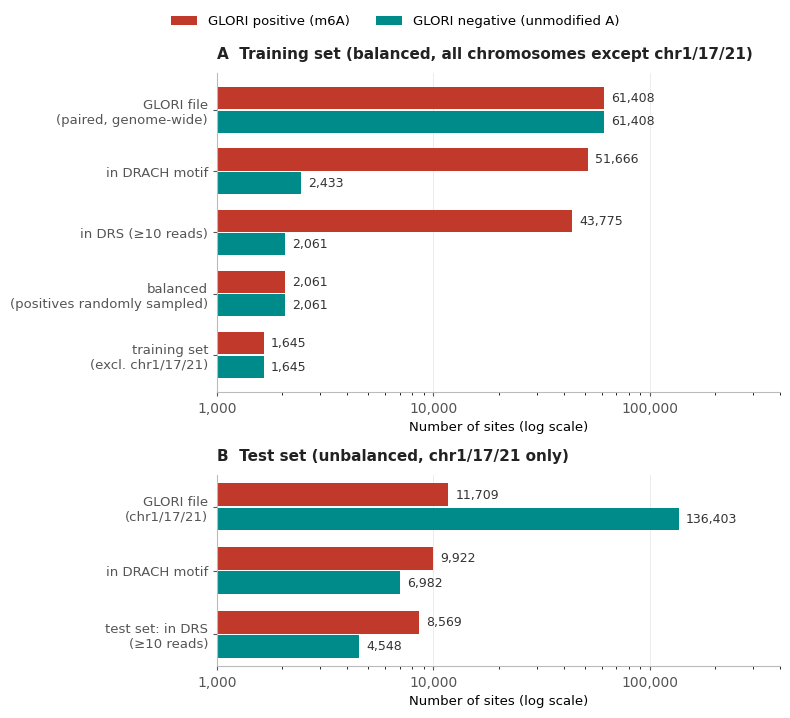

In [ ]:

"""
Site funnel figure: how GLORI sites become the training and test sets.
Two panels (training / test), positives vs negatives at each filtering step.
Log x-axis so the small final counts stay visible next to the large file sizes.
"""
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
 
POS_COLOR = "#1B365D"   # GLORI positives (m6A)
NEG_COLOR = "#D4A373"   # GLORI negatives (unmodified A)
 
# ---- numbers (edit here if anything changes) ------------------------------
train_steps = [
    ("GLORI file\n(paired, genome-wide)",        61_408, 61_408),
    ("in DRACH motif",                           51_666,  2_433),
    ("in DRS (≥10 reads)",                       43_775,  2_061),
    ("balanced\n(positives randomly sampled)",    2_061,  2_061),
    ("training set\n(excl. chr1/17/21)",          1_645,  1_645),
]
test_steps = [
    ("GLORI file\n(chr1/17/21)",                 11_709, 136_403),
    ("in DRACH motif",                            9_922,   6_982),
    ("test set: in DRS\n(≥10 reads)",             8_569,   4_548),
]
# ---------------------------------------------------------------------------
 
def panel(ax, steps, title, xmax):
    labels = [s[0] for s in steps]
    pos = [s[1] for s in steps]
    neg = [s[2] for s in steps]
    y = range(len(steps))
    h = 0.36
    ax.barh([i - h / 2 - 0.01 for i in y], pos, height=h, color=POS_COLOR, label="GLORI positive (m6A)")
    ax.barh([i + h / 2 + 0.01 for i in y], neg, height=h, color=NEG_COLOR, label="GLORI negative (unmodified A)")
    for i in y:
        ax.text(pos[i] * 1.08, i - h / 2 - 0.01, f"{pos[i]:,}", va="center", fontsize=9, color="#333")
        ax.text(neg[i] * 1.08, i + h / 2 + 0.01, f"{neg[i]:,}", va="center", fontsize=9, color="#333")
    ax.set_yticks(list(y))
    ax.set_yticklabels(labels, fontsize=9.5)
    ax.invert_yaxis()                      # first step on top
    ax.set_xscale("log")
    ax.set_xlim(1_000, xmax)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.set_xlabel("Number of sites (log scale)", fontsize=9.5)
    ax.set_title(title, fontsize=11, loc="left", fontweight="bold", color="#222", pad=10)
    ax.grid(axis="x", color="#ececec", linewidth=0.7)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color("#bbbbbb")
    ax.spines["bottom"].set_color("#bbbbbb")
    ax.tick_params(colors="#555", length=3)
 
fig, axes = plt.subplots(
    2, 1, figsize=(8, 7.2),
    gridspec_kw={"height_ratios": [len(train_steps), len(test_steps)]},
)
panel(axes[0], train_steps, "A  Training set (balanced, all chromosomes except chr1/17/21)", 400_000)
panel(axes[1], test_steps,  "B  Test set (unbalanced, chr1/17/21 only)", 400_000)
 
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False,
           fontsize=9.5, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig("site_funnel.png", dpi=300, bbox_inches="tight")
fig.savefig("site_funnel.pdf", bbox_inches="tight")     # vector version for Overleaf
print("saved site_funnel.png and site_funnel.pdf")
